In [154]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
import matplotlib.pyplot as plt

In [ ]:
df= pd.read_pickle("../data/jan_2025_5.pickle")
# df= pd.read_pickle("../data/keep/uniform_sparse_cs_Nov_2024.pickle")

print(df.columns)

Index(['sqt_n', 'm', 'k', 'sigma', 'lambda_', 'tol', 'max_iter', 'img',
       'sampling_type', 'adapted_sampling', 'seed', 're', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr', 'optim_info'],
      dtype='object')


In [156]:
df.columns

Index(['sqt_n', 'm', 'k', 'sigma', 'lambda_', 'tol', 'max_iter', 'img',
       'sampling_type', 'adapted_sampling', 'seed', 're', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr', 'optim_info'],
      dtype='object')

In [157]:
df_vals(df)

'sqt_n':
[400]
----------------------------------------
'm':
[   100    350   1223   4278  14961  52324 182995 640000]
----------------------------------------
'k':
[ 64000 320000]
----------------------------------------
'sigma':
[ 0.  1. 10.]
----------------------------------------
'lambda_':
[1.e-02 1.e-05 1.e-09]
----------------------------------------
'tol':
[1.e-03 1.e-06 1.e-10]
----------------------------------------
'max_iter':
[1000000.]
----------------------------------------
'img':
Categorical:  ['phantom', 'camera']
Categories (2, object): ['camera', 'phantom']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'seed':
min: 9403532.00, max: 4293462305.00, mean: 2195731004.11, std: 1257812191.78
----------------------------------------
're':
min: 0.02, max: 1.06, mean: 0.37, std: 0.38
------------

/opt/homebrew/anaconda3/envs/torch/lib/python3.12/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


In [170]:
df_wr = df[df['sampling_type']=='wr']
mydf = df_wr[df_wr['adapted_sampling']==True]
mydf = df_wr[mydf['img']=="phantom"]

In [171]:
mydf['prop_m'] = mydf['m']/mydf['sqt_n']**2

/var/folders/9d/dmf_3v3d5cg6drc619z979yc0000gn/T/ipykernel_1124/3206528644.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mydf['prop_m'] = mydf['m']/mydf['sqt_n']**2


In [172]:
mydf['unique_meas'] = mydf['indices'].apply(lambda x: len(np.unique(x)))/ mydf['sqt_n']**2

/var/folders/9d/dmf_3v3d5cg6drc619z979yc0000gn/T/ipykernel_1124/3877919747.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mydf['unique_meas'] = mydf['indices'].apply(lambda x: len(np.unique(x)))/ mydf['sqt_n']**2


In [173]:
mydf['unique_meas'].dtype

dtype('float64')

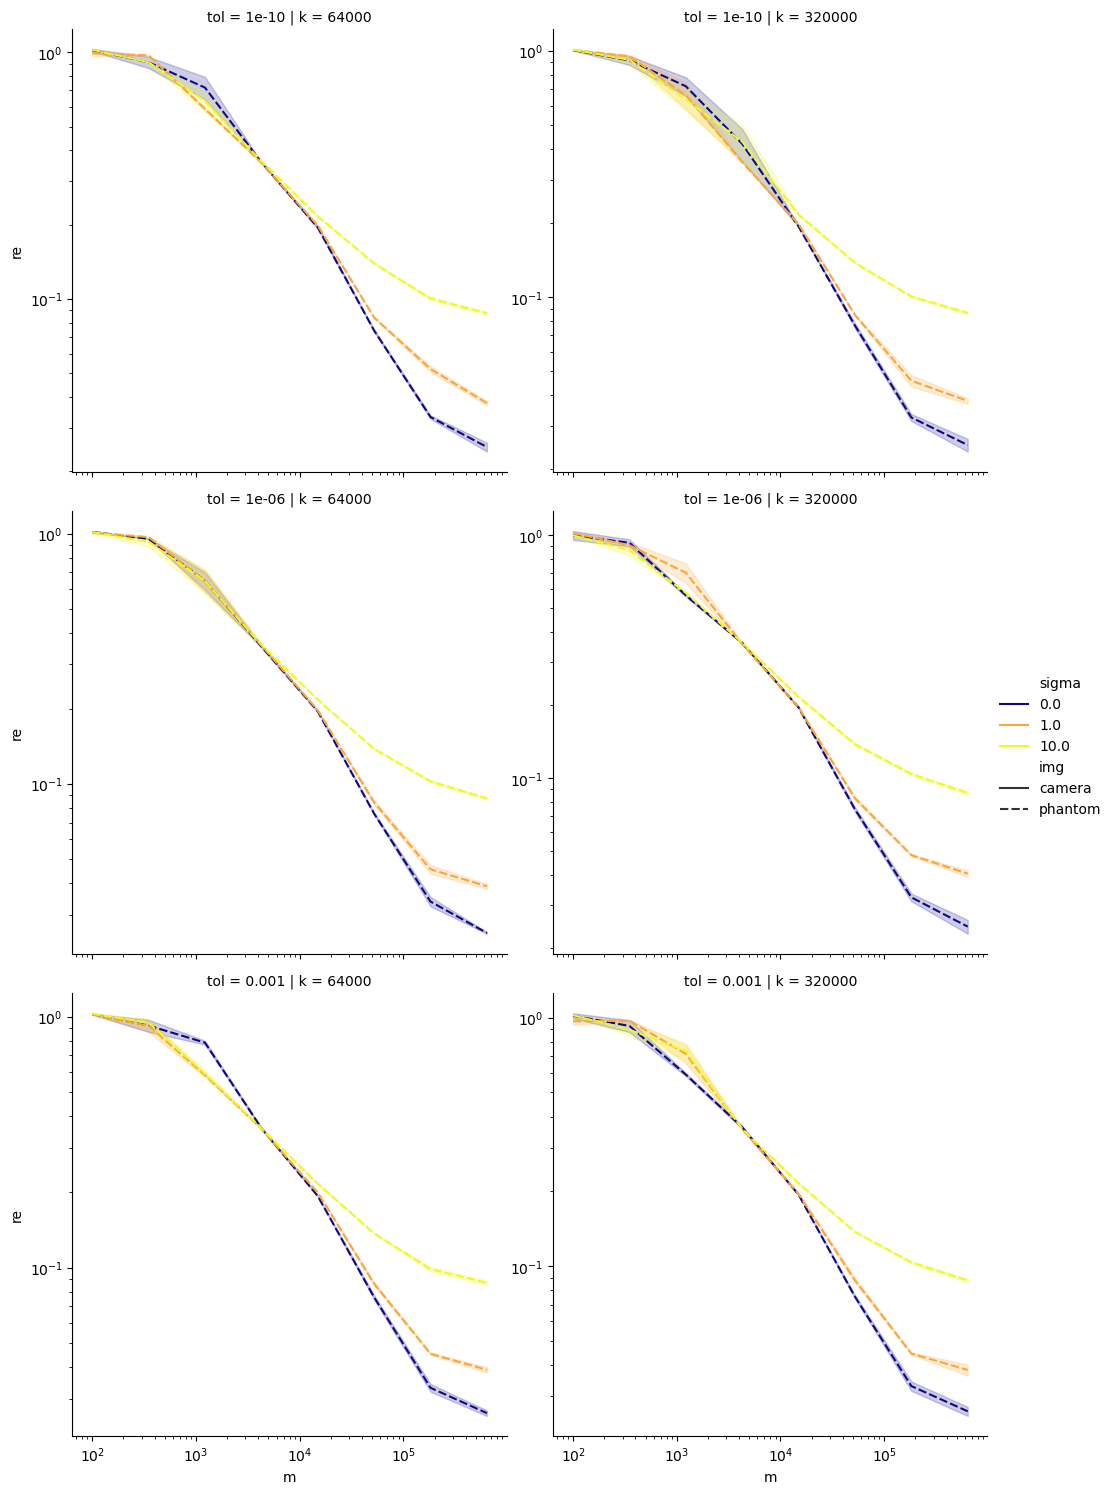

In [177]:
doubledf=melt_and_keep(mydf, ["re","unique_meas"])
#sns.relplot(mydf, kind = "line", x = "m", y="re", col="lambda_", style="img", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
g=sns.relplot(mydf, kind = "line", x = "m", y="re", row="tol", col="k", style="img", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

In [163]:
kkjdf_wr

NameError: name 'kkjdf_wr' is not defined